In [1]:
import pacmap 
import numpy        as np
import pandas       as pd
import umap.umap_   as umap

from tqdm                               import tqdm
from sklearn.preprocessing              import StandardScaler, MinMaxScaler
from sklearn.cluster                    import DBSCAN

from utils.Preprocessing                import PreProcessData
from utils.plotFigures                  import linePlot, lineAndScatterPlot, scatterPlot3D, scatterPlot2D
#from clustering.clusteringTimeSeries    import ClusteringTimeSeries
from clustering.plotClustering          import ClusteringResults

In [2]:
preData = PreProcessData()
df1Raw  = preData.dataLoading(typeFile='h5')
preData.additionEfficiencyVar()
preData.splitTimeSeries()
dfHealthy, dfUnhealthy = preData.getHealthyState()

scaler          = MinMaxScaler() 
scaledHealthy   = preData.normalizeData(data   = dfHealthy, 
                                        scaler = scaler)
scaledUnhealthy = preData.normalizeData(data   = dfUnhealthy,
                                        scaler = scaler)

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\Preprocessing.py:269: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.healthyData    = pd.concat([self.healthyData, healthyPeriod],     ignore_index=True)
c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\Preprocessing.py:269: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.healthyData    = pd.concat([self.healthyData, healthyPeriod],     ignore_index=True)
c:\Users\CAEX\Desktop\Diego\Crusher 

In [3]:
linePlot(data   = scaledHealthy, 
         x      = 'tiempo', 
         y      = 'corriente(A)', 
         color  = 'trajectory')

In [4]:
# Declarate models for clustering and dimensionality reduction for manipulable variables

dfEfficiencyVar = scaledHealthy[preData.efficiencyCr1 + preData.newEfficiencyCr1]

clusteringModels    = {'umap':   DBSCAN(min_samples = 150,
                                        eps         = 2.2),

                       'pacmap': DBSCAN(min_samples = 200,
                                        eps         = 3)} 

dimReductionModels  = {'umap':   umap.UMAP(n_components = 2, 
                                           random_state = 40),

                       'pacmap': pacmap.PaCMAP(n_components = 2, 
                                               random_state = 40, 
                                               save_tree    = True)}

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\pacmap\pacmap.py:828: UserWarning:




In [5]:
Clusters = ClusteringResults(data                = scaledHealthy, 
                             dataNormalized      = dfEfficiencyVar, 
                             clusteringModels    = clusteringModels, 
                             dimReductionModels  = dimReductionModels)

In [6]:
# Train dimensionality reduction models wiht a trajectory
Clusters.trainPrevious(trainTrajectory='15')

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\umap\umap_.py:1945: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



In [7]:
# Clusters are calculated in embedding space for each trajectory
for trajectory in tqdm(Clusters.trajectories[:6]):
    Clusters.getResults(trajectory)

100%|██████████| 6/6 [00:30<00:00,  5.07s/it]


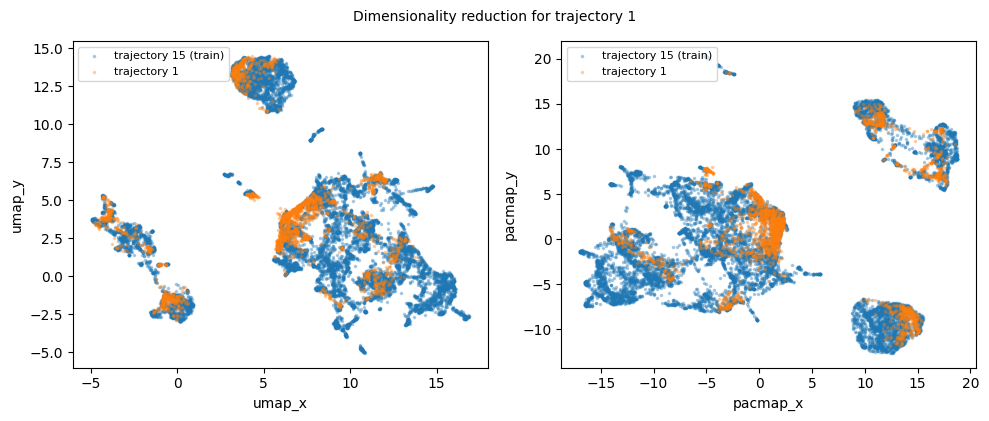

In [8]:
Clusters.plotEmbedding(nfigures=1)

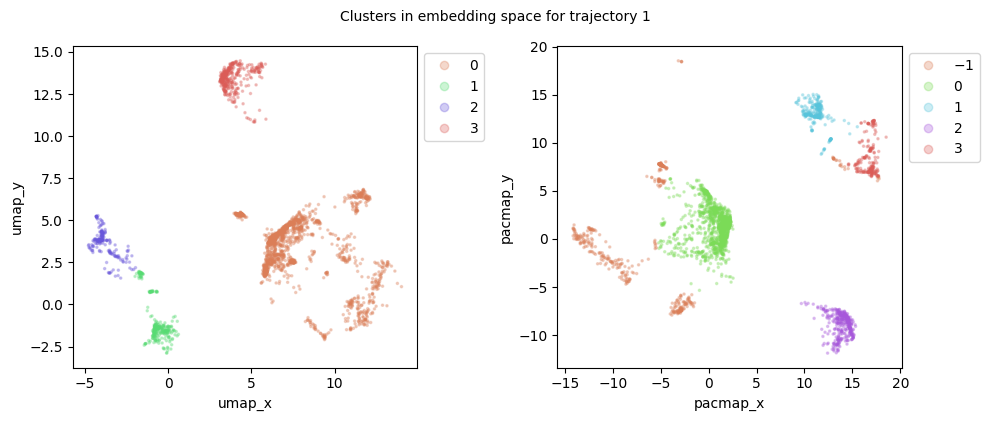

In [9]:
Clusters.plotResults(nfigures=1)

In [10]:
dfEfficiencyVar = scaledUnhealthy[preData.efficiencyCr1 + preData.newEfficiencyCr1]

clusteringModels    = {'umap':   DBSCAN(min_samples = 150,
                                        eps         = 2.2),

                       'pacmap': DBSCAN(min_samples = 200,
                                        eps         = 3  )} 

dimReductionModels  = Clusters.dimReductionModels # Trained models

In [11]:
ClustersUnhealthy = ClusteringResults(data                = scaledUnhealthy, 
                                      dataNormalized      = dfEfficiencyVar, 
                                      clusteringModels    = clusteringModels, 
                                      dimReductionModels  = dimReductionModels)

In [12]:
# trained embedding space with healthy data
ClustersUnhealthy.trainTrajectory = Clusters.trainTrajectory
ClustersUnhealthy.embeddingTrain = Clusters.embeddingTrain 

In [13]:
# Get clusters for each trajectory
for trajectory in tqdm(ClustersUnhealthy.trajectories[:6]):
    ClustersUnhealthy.getResults(trajectory)

100%|██████████| 6/6 [00:23<00:00,  3.83s/it]


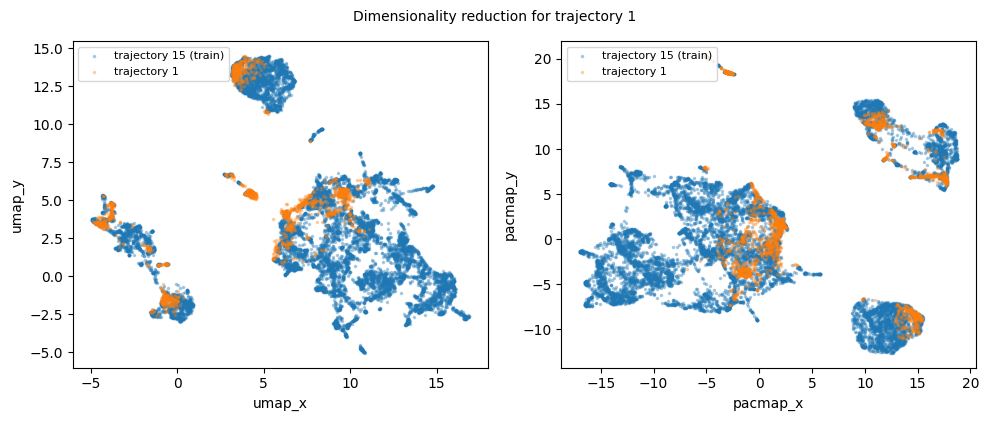

In [14]:
ClustersUnhealthy.plotEmbedding(nfigures=1)

In [15]:
trajectory = '7'
a=Clusters.clustersResults[trajectory][['pacmap_x', 'pacmap_y']].copy()
b=ClustersUnhealthy.clustersResults[trajectory][['pacmap_x', 'pacmap_y']].copy()
a['health'] = 'healthy'
b['health'] = 'unhealthy'

In [16]:
scatterPlot2D(data=pd.concat([a,b]), x='pacmap_x', y='pacmap_y', color='health', title='Comparison between healthy and unhealthy data')

# Unified clusters

In [17]:
Clusters.getSimilarClusters(algorithm = 'umap', threshold = 5)
Clusters.unifyClusters(algorithm='umap')

Clusters.getSimilarClusters(algorithm = 'pacmap', threshold = 5)
Clusters.unifyClusters(algorithm='pacmap')

In [40]:
import plotly.graph_objects as go
import networkx as nx

def plotGraph():
    # Assign colors to nodes based on the connected component they belong to
    colors = ['red', 'royalblue', 'green', 'orange', 'purple', 'yellow']  # Change length of colors
    nodeColors = {}
    edgeColors = {}

    for i, component in enumerate(Clusters.connectedComponents):
        # Add colors to node and edges
        for node in component:
            nodeColors[node] = colors[i % len(colors)]

        for edge in Clusters.Graph.edges():
            if edge[0] in component and edge[1] in component:
                edgeColors[edge] = colors[i % len(colors)]

    # Add position to graph
    pos = {}
    for node in Clusters.Graph.nodes():
        pos[node] = (node[0], node[1])

    # Create Plotly figure
    fig = go.Figure()

    # Add nodes
    for node in Clusters.Graph.nodes():
        fig.add_trace(go.Scatter(x=[pos[node][0]], y=[pos[node][1]],
                                 mode='markers',
                                 marker=dict(size=10, color=nodeColors[node]),
                                 text=str(node),
                                 hoverinfo='text'))

    # Add edges
    for edge in Clusters.Graph.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        fig.add_trace(go.Scatter(x=[x0, x1], y=[y0, y1],
                                 mode='lines',
                                 line=dict(color=edgeColors[edge], width=2),
                                 hoverinfo='none'))

    # Update layout
    fig.update_layout(title="Assignment found between similar clusters",
                      xaxis_title="trajectories",
                      yaxis_title="clusters",
                      showlegend=False,
                      width=600,  
                      height=500)

    fig.show()

In [41]:
plotGraph()

In [20]:
# Clusters.plotResults(nfigures=6, 
#                      label_color='real_cluster')

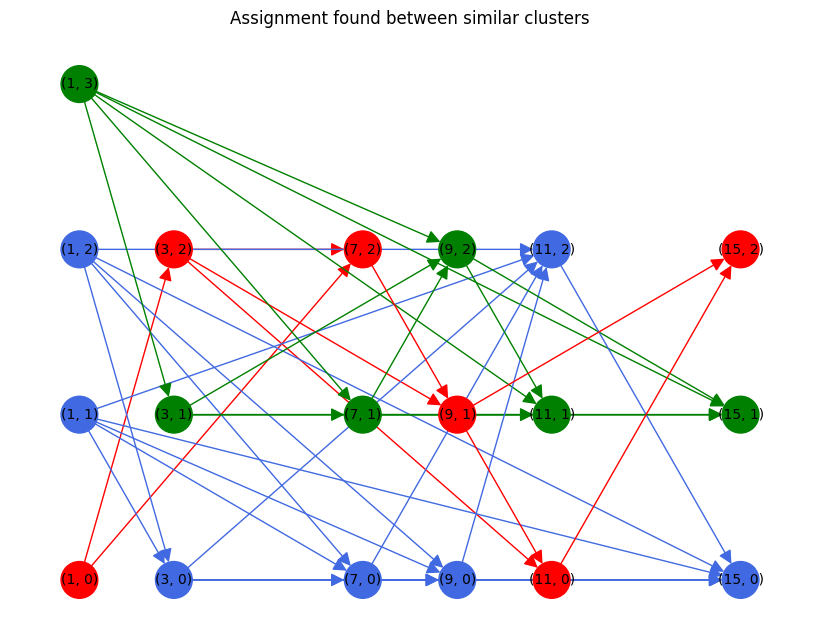

In [21]:
Clusters.plotGraph()

In [ ]:
# Get clusters for each trajectory
for trajectory in tqdm(['1', '3']):
    Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 200, eps = 3.3)} 
    Embedding1.getResults(trajectory)


for trajectory in tqdm(['7', '9']):
    Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 200, eps = 2.8)} 
    Embedding1.getResults(trajectory)

for trajectory in tqdm(['11', '15']):
    Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 200, eps = 2.5)} 
    Embedding1.getResults(trajectory)

trajectory = '17'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 250, eps = 3.9)} 
Embedding1.getResults(trajectory)

trajectory = '19'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 250, eps = 8)} 
Embedding1.getResults(trajectory)

trajectory = '21'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 250, eps = 6)} 
Embedding1.getResults(trajectory)

trajectory = '23'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 350, eps = 4)} 
Embedding1.getResults(trajectory)

trajectory = '25'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 400, eps = 6)} 
Embedding1.getResults(trajectory)

trajectory = '27'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 200, eps = 6)}
Embedding1.getResults(trajectory)

trajectory = '29'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 200, eps = 2.7)}
Embedding1.getResults(trajectory)

trajectory = '37'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 180, eps = 2.2)}
Embedding1.getResults(trajectory)

trajectory = '39'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 100, eps = 2.2)}
Embedding1.getResults(trajectory)

trajectory = '45'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 100, eps = 2)}
Embedding1.getResults(trajectory)

trajectory = '49'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 190, eps = 2.1)}
Embedding1.getResults(trajectory)

trajectory = '51'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 100, eps = 3.1)}
Embedding1.getResults(trajectory)

trajectory = '55'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 100, eps = 2)}
Embedding1.getResults(trajectory)

trajectory = '61'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 100, eps = 2)}
Embedding1.getResults(trajectory)

trajectory = '63'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 20, eps = 3)}
Embedding1.getResults(trajectory)

trajectory = '65'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 100, eps = 3)}
Embedding1.getResults(trajectory)

trajectory = '67'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 70, eps = 2)}
Embedding1.getResults(trajectory)

trajectory = '71'
Embedding1.clusteringModels = {'pacmap': DBSCAN(min_samples = 100, eps = 3)}
Embedding1.getResults(trajectory)

In [ ]:
import matplotlib.pyplot as plt 
from matplotlib.colors                  import ListedColormap
import seaborn as sns

def plotClusters(self, trajectory, label_color='cluster', save=False):
    cmap  = ListedColormap(sns.color_palette("hls", 256).as_hex()[10:])
    ncols = len(self.algorithms)



    fig, axes  = plt.subplots(nrows   = 1, 
                                ncols   = ncols, 
                                figsize = (5*ncols, 4))            
    if ncols == 1:
        axes = [axes]
    
    data       = self.clustersResults[trajectory] #self.getTrajectory(trajectory)

    for j in range(ncols):
        algorithm = self.algorithms[j]
        scatterplot = axes[j].scatter(x      = data[f'{algorithm}_x'], 
                                        y      = data[f'{algorithm}_y'], 
                                        c      = data[f'{label_color}_{algorithm}'].astype('int'), 
                                        cmap   = cmap,                
                                        marker = '.',
                                        alpha  = 0.3,
                                        s      = 10 )
        
        axes[j].set_xlabel(f'{algorithm}_x')
        axes[j].set_ylabel(f'{algorithm}_y')
        axes[j].legend(*scatterplot.legend_elements(), 
                        bbox_to_anchor = (1, 1),
                        loc            = 'upper left')
        
    fig.tight_layout()
    fig.suptitle(f'Clusters in embedding space for trajectory {trajectory}', 
                    fontsize = 10, 
                    y        = 1.04)

In [ ]:
# data                    = Embedding1.embeddingTrain[['pacmap_x', 'pacmap_y']].copy()
# scatterPlot2D(data, x='pacmap_x', y='pacmap_y', color=None) # 'cluster')

In [ ]:
import matplotlib.pyplot as plt 
from matplotlib.colors                  import ListedColormap
import seaborn as sns

def plotClusters(self, trajectory, label_color='cluster', save=False):
    cmap  = ListedColormap(sns.color_palette("hls", 256).as_hex()[10:])
    ncols = len(self.algorithms)



    fig, axes  = plt.subplots(nrows   = 1, 
                                ncols   = ncols, 
                                figsize = (5*ncols, 4))            
    if ncols == 1:
        axes = [axes]
    
    data       = self.clustersResults[trajectory] #self.getTrajectory(trajectory)

    for j in range(ncols):
        algorithm = self.algorithms[j]
        scatterplot = axes[j].scatter(x      = data[f'{algorithm}_x'], 
                                        y      = data[f'{algorithm}_y'], 
                                        c      = data[f'{label_color}_{algorithm}'].astype('int'), 
                                        cmap   = cmap,                
                                        marker = '.',
                                        alpha  = 0.3,
                                        s      = 10 )
        
        axes[j].set_xlabel(f'{algorithm}_x')
        axes[j].set_ylabel(f'{algorithm}_y')
        axes[j].legend(*scatterplot.legend_elements(), 
                        bbox_to_anchor = (1, 1),
                        loc            = 'upper left')
        
    fig.tight_layout()
    fig.suptitle(f'Clusters in embedding space for trajectory {trajectory}', 
                    fontsize = 10, 
                    y        = 1.04)